In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import os

os.makedirs("data", exist_ok=True)

print("data folder created successfully!")

data folder created successfully!


In [ ]:
customers = """customer_id,name,city,city_tier,signup_date,acquisition_source
C001,Aarav,Mumbai,1,2026-01-07,Organic
C002,Vivaan,Delhi,1,2026-02-27,Referral
C003,Aditi,Mumbai,1,2026-06-23,Organic
C004,Ananya,Lucknow,2,2026-01-23,Organic
C005,Ishaan,Mumbai,1,2026-01-08,Referral
C006,Diya,Delhi,1,2026-05-10,Organic
C007,Kabir,Lucknow,2,2026-02-20,Organic
C008,Meera,Lucknow,2,2026-04-18,Ad
C009,Rohan,Lucknow,2,2026-03-13,Social
C010,Sara,Mumbai,1,2026-02-10,Organic
C011,Arjun,Bangalore,1,2026-03-13,Referral
C012,Priya,Bangalore,1,2026-01-27,Referral
C013,Karan,Mumbai,1,2026-04-02,Social
C014,Neha,Lucknow,2,2026-03-09,Social
C015,Yash,Jaipur,2,2026-05-18,Referral
C016,Pooja,Jaipur,2,2026-01-21,Organic
C017,Rahul,Lucknow,2,2026-04-03,Organic
C018,Simran,Mumbai,1,2026-01-12,Organic
C019,Dev,Bangalore,1,2026-01-21,Social
C020,Tara,Mumbai,1,2026-04-08,Ad
C021,Aryan,Bangalore,1,2026-02-11,Ad
C022,Kavya,Delhi,1,2026-06-21,Ad
C023,Nikhil,Mumbai,1,2026-06-05,Organic
C024,Riya,Lucknow,2,2026-03-04,Referral
C025,Varun,Jaipur,2,2026-03-11,Social
C026,Isha,Lucknow,2,2026-02-26,Organic
C027,Manav,Mumbai,1,2026-02-28,Social
C028,Shreya,Bangalore,1,2026-04-13,Ad
C029,Tanish,Delhi,1,2026-05-26,Social
C030,Anika,Bangalore,1,2026-02-24,Organic
C031,Aditya,Jaipur,2,2026-06-14,Ad
C032,Naina,Bangalore,1,2026-02-05,Ad
C033,Siddharth,Lucknow,2,2026-05-18,Ad
C034,Zara,Lucknow,2,2026-04-20,Social
C035,Krishna,Jaipur,2,2026-04-03,Ad
C036,Aisha,Delhi,1,2026-05-11,Ad
C037,Rudra,Mumbai,1,2026-01-29,Referral
C038,Myra,Delhi,1,2026-06-24,Ad
C039,Om,Mumbai,1,2026-04-09,Ad
C040,Vanya,Jaipur,2,2026-05-16,Ad
C041,Ayaan,Lucknow,2,2026-01-03,Organic
C042,Sanya,Mumbai,1,2026-06-24,Social
C043,Reyansh,Bangalore,1,2026-06-14,Ad
C044,Aria,Bangalore,1,2026-04-22,Referral
C045,Vihaan,Mumbai,1,2026-03-09,Social"""

with open("data/customers.csv", "w") as f:
    f.write(customers)

print("customers.csv created successfully!")

customers.csv created successfully!


In [ ]:
products = """product_id,product_name,category,price
P01,Onion Hair Oil,Haircare,349
P02,Onion Shampoo,Haircare,399
P03,Argan Hair Mask,Haircare,599
P04,Anti-Hairfall Serum,Haircare,649
P05,Rice Water Conditioner,Haircare,349
P06,Vitamin C Face Wash,Skincare,249
P07,Vitamin C Serum,Skincare,699
P08,Tea Tree Face Wash,Skincare,229
P09,Ubtan Face Mask,Skincare,299
P10,Rice Sunscreen SPF50,Skincare,449
P11,Milky Soft Baby Lotion,Babycare,299
P12,Baby Shampoo,Babycare,249
P13,Baby Massage Oil,Babycare,279
P14,Charcoal Deodorant,PersonalCare,199
P15,Tea Tree Body Wash,PersonalCare,349
P16,Aloe Vera Gel,PersonalCare,199"""

with open("data/products.csv", "w") as f:
    f.write(products)

print("products.csv created successfully!")

products.csv created successfully!


In [ ]:
print("Customers:", pd.read_csv("data/customers.csv").shape)
print("Products:", pd.read_csv("data/products.csv").shape)

Customers: (45, 6)
Products: (16, 4)


In [ ]:
orders_data = """order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,rating,returned
O0001,C012,P04,2026-03-18,2,10,upi,2,0
O0002,C024,P06,2026-05-16,1,30,UPI,1,0
O0003,C008,P12,2026-03-20,2,0,COD,1,1
O0004,C032,P03,2026-05-17,3,30,UPI,5,0
O0005,C011,P09,2026-06-05,1,10,Card,3,0
O0006,C026,P12,2026-05-13,1,0,Card,3,0
O0007,C002,P08,2026-01-02,1,10,COD,1,0
O0008,C003,P11,2026-03-02,1,10,COD,,0
O0009,C037,P16,2026-05-02,1,0,UPI,4,0
O0010,C023,P14,2026-01-14,1,0,Card,1,0
O0011,C026,P11,2026-01-28,25,0,COD,2,1
O0012,C028,P06,2026-03-05,1,0,UPI,1,1
O0013,C042,P01,2026-03-02,3,,COD,4,0
O0014,C004,P06,2026-04-10,1,30,cod,3,0
O0015,C028,P16,2026-03-17,1,,COD,3,1
O0016,C004,P02,2026-05-09,1,0,UPI,5,0
O0017,C006,P06,2026-01-18,1,,Card,5,0
O0018,C016,P02,2026-04-18,2,20,CARD,3,0
O0019,C014,P11,2026-04-12,1,30,COD,3,0
O0020,C005,P01,2026-05-25,1,10,UPI,5,1
O0021,C017,P05,2026-01-18,3,10,UPI,,0
O0022,C035,P10,2026-06-17,2,20,Card,1,0
O0023,C009,P09,2026-01-28,1,20,Card,5,0
O0024,C014,P11,2026-06-12,1,20,UPI,1,0
O0025,C006,P14,2026-01-12,2,20,COD,2,0
O0026,C029,P14,2026-01-29,1,10,COD,5,0
O0027,C003,P12,2026-02-07,1,20,card,1,1
O0028,C023,P07,2026-06-20,2,30,COD,5,0
O0029,C010,P08,2026-02-15,2,20,UPI,4,1
O0030,C043,P08,2026-06-29,1,,COD,2,0
O0031,C013,P15,2026-02-28,1,30,COD,3,0
O0032,C018,P03,2026-03-13,3,,Card,1,0
O0033,C008,P09,2026-03-09,1,20,COD,3,0
O0034,C028,P04,2026-05-28,1,30,COD,1,1
O0035,C034,P07,2026-01-18,1,20,UPI,1,0
O0036,C020,P10,2026-03-25,2,,Card,2,0
O0037,C027,P13,2026-02-14,2,0,Card,3,0
O0038,C019,P07,2026-05-29,1,30,Card,4,0
O0039,C044,P07,2026-02-13,1,20,Card,1,0
O0040,C016,P10,2026-02-20,1,30,cod,5,1
O0041,C005,P15,2026-06-11,1,30,Card,4,0
O0042,C026,P08,2026-06-26,1,0,COD,4,0
O0043,C015,P06,2026-06-28,2,10,Card,1,1
O0044,C030,P05,2026-06-20,2,20,Card,4,0
O0045,C040,P14,2026-05-21,2,30,Card,4,0
O0046,C017,P08,2026-03-12,2,10,UPI,3,0
O0047,C029,P03,2026-03-02,2,0,COD,2,1
O0048,C010,P08,2026-02-09,1,30,Card,3,1
O0049,C035,P15,2026-02-22,1,0,UPI,5,0
O0050,C025,P16,2026-04-01,1,30,COD,5,1
O0051,C035,P08,2026-03-11,1,20,Card,4,1
O0052,C011,P15,2026-06-09,3,0,CARD,1,0
O0053,C042,P14,2026-04-29,1,20,cod,,1
O0054,C030,P11,2026-04-08,1,30,COD,,0
O0055,C006,P16,2026-05-19,1,10,COD,1,0
O0056,C042,P02,2026-03-05,2,10,COD,2,1
O0057,C009,P16,2026-05-25,2,20,UPI,3,0
O0058,C011,P04,2026-02-11,2,0,UPI,3,0
O0059,C037,P13,2026-02-20,1,10,COD,1,0
O0060,C020,P04,2026-05-25,2,30,UPI,3,0
O0061,C005,P11,2026-04-18,1,20,UPI,4,0
O0062,C010,P14,2026-05-14,1,30,UPI,4,0
O0063,C028,P09,2026-03-04,1,30,UPI,2,1
O0064,C030,P13,2026-05-07,1,10,UPI,3,0
O0065,C017,P11,2026-06-02,1,0,Card,5,0
O0066,C013,P03,2026-04-15,1,30,card,4,0
O0067,C029,P01,2026-02-26,1,20,Card,4,0
O0068,C036,P12,2026-05-21,1,20,Card,3,0
O0069,C017,P08,2026-02-19,1,10,CARD,2,0
O0070,C014,P16,2026-05-31,1,20,UPI,1,0
O0071,C013,P10,2026-02-15,1,10,Card,3,0
O0072,C003,P02,2026-06-28,1,30,UPI,1,0
O0073,C001,P10,2026-04-23,1,20,Card,,0
O0074,C008,P03,2026-01-19,1,10,Card,2,0
O0075,C037,P10,2026-03-05,1,10,COD,5,0
O0076,C025,P15,2026-03-18,3,20,UPI,5,0
O0077,C040,P02,2026-01-26,2,10,UPI,3,0
O0078,C043,P03,2026-02-14,1,30,Card,4,0
O0079,C039,P16,2026-03-01,1,30,cod,,1
O0080,C044,P08,2026-06-10,3,,Card,4,0
O0081,C008,P08,2026-03-10,2,10,UPI,3,1
O0082,C039,P10,2026-04-30,1,,Card,5,0
O0083,C035,P16,2026-06-03,1,20,COD,5,0
O0084,C017,P01,2026-06-22,1,0,UPI,3,0
O0085,C037,P02,2026-02-14,2,,Card,2,0
O0086,C038,P14,2026-05-06,2,30,UPI,3,0
O0087,C021,P04,2026-03-26,2,30,Card,5,0
O0088,C003,P15,2026-03-06,1,30,Card,,0
O0089,C001,P15,2026-02-18,1,30,Card,4,0
O0090,C004,P07,2026-02-03,1,30,UPI,1,0
O0091,C002,P08,2026-03-21,2,0,Card,2,0
O0092,C008,P15,2026-06-15,3,20,upi,5,0
O0093,C018,P14,2026-05-01,2,30,COD,2,0
O0094,C039,P05,2026-03-12,2,20,UPI,5,0
O0095,C018,P01,2026-03-18,1,30,UPI,,0
O0096,C029,P16,2026-05-22,1,20,UPI,2,0
O0097,C016,P13,2026-04-16,1,30,COD,4,0
O0098,C043,P05,2026-01-10,30,0,COD,1,0
O0099,C029,P04,2026-04-27,1,10,COD,1,1
O0100,C031,P09,2026-06-27,1,20,Card,5,1
O0101,C025,P11,2026-05-05,2,0,UPI,2,1
O0102,C041,P10,2026-01-24,3,0,Card,4,1
O0103,C011,P10,2026-01-12,3,20,CARD,3,1
O0104,C028,P05,2026-04-16,1,10,Card,2,0
O0105,C006,P13,2026-03-03,2,10,card,4,0
O0106,C041,P09,2026-06-20,1,20,COD,5,0
O0107,C011,P03,2026-03-30,1,30,UPI,3,0
O0108,C030,P10,2026-04-09,1,30,UPI,5,0
O0109,C023,P10,2026-03-17,3,30,COD,3,0
O0110,C001,P02,2026-05-08,3,10,UPI,5,0
O0111,C023,P08,2026-06-08,2,10,COD,1,0
O0112,C041,P02,2026-04-23,1,10,COD,1,1
O0113,C019,P11,2026-02-14,2,20,COD,5,0
O0114,C033,P09,2026-03-07,2,20,UPI,3,0
O0115,C008,P15,2026-02-06,3,30,UPI,5,0
O0116,C024,P03,2026-01-04,2,20,COD,3,1
O0117,C038,P13,2026-04-06,2,0,COD,5,1
O0118,C036,P11,2026-02-26,3,30,card,,0
O0119,C042,P14,2026-01-12,1,30,UPI,1,0
O0120,C007,P08,2026-02-04,2,30,CARD,5,0
O0121,C010,P14,2026-05-06,2,20,Card,1,0
O0122,C024,P07,2026-03-02,1,20,UPI,5,1
O0123,C042,P12,2026-03-12,1,30,COD,1,1
O0124,C043,P07,2026-06-02,2,20,UPI,,1
O0125,C009,P07,2026-05-22,1,10,COD,3,1
O0126,C010,P01,2026-02-07,1,10,UPI,1,0
O0127,C043,P01,2026-04-02,1,20,UPI,1,0
O0128,C012,P09,2026-04-18,1,30,Card,4,0
O0129,C024,P04,2026-02-26,1,20,UPI,4,1
O0130,C042,P01,2026-05-03,1,0,UPI,4,0
O0131,C029,P03,2026-03-24,2,20,card,5,1
O0132,C041,P11,2026-06-02,1,30,Card,1,0
O0133,C008,P07,2026-02-28,1,30,Card,4,0
O0134,C007,P11,2026-06-20,1,30,COD,,0
O0135,C006,P03,2026-01-25,1,10,Card,5,0
O0136,C004,P11,2026-04-16,2,30,Card,1,0
O0137,C019,P10,2026-05-28,1,30,CARD,2,0
O0138,C007,P12,2026-04-05,2,10,COD,4,1
O0139,C036,P01,2026-06-18,2,10,UPI,3,0
O0140,C020,P11,2026-02-16,1,30,UPI,1,0
O0141,C010,P01,2026-05-16,1,20,COD,2,1
O0142,C024,P10,2026-05-26,2,10,Card,2,0
O0143,C040,P02,2026-03-11,2,30,Card,4,0
O0144,C018,P07,2026-01-30,2,30,card,5,0
O0145,C043,P10,2026-04-12,1,10,UPI,3,1
O0146,C014,P05,2026-03-16,2,30,Card,2,1
O0147,C009,P13,2026-02-28,1,20,Card,1,0
O0148,C026,P02,2026-04-28,1,30,UPI,5,0
O0149,C026,P14,2026-04-14,1,30,COD,,1
O0150,C006,P14,2026-03-04,2,0,Card,4,0
O0151,C020,P11,2026-02-13,1,10,COD,3,0
O0152,C023,P05,2026-02-07,1,,COD,1,1
O0153,C012,P16,2026-05-25,1,20,UPI,3,0
O0154,C010,P15,2026-04-24,1,0,CARD,3,0
O0155,C033,P03,2026-04-26,1,20,COD,1,1
O0156,C042,P03,2026-05-10,2,,Card,4,0
O0157,C037,P07,2026-05-02,1,30,card,1,0
O0158,C022,P03,2026-02-14,1,30,COD,5,0
O0159,C034,P06,2026-03-14,1,0,Card,3,0
O0160,C005,P11,2026-06-23,1,10,Card,3,0
O0161,C006,P05,2026-03-21,3,30,UPI,2,0
O0162,C039,P03,2026-04-07,1,10,Card,5,0
O0163,C006,P14,2026-01-05,1,10,Card,,0
O0164,C032,P07,2026-02-05,1,0,COD,,1
O0165,C035,P02,2026-06-08,2,10,COD,2,1
O0166,C040,P06,2026-01-12,2,10,Card,4,0
O0167,C040,P10,2026-04-25,2,30,COD,2,1
O0168,C024,P15,2026-03-14,1,30,UPI,,0
O0169,C013,P05,2026-01-14,2,,Card,5,0
O0170,C008,P10,2026-02-11,1,10,cod,4,0
O0171,C006,P08,2026-03-31,2,30,UPI,5,0
O0172,C024,P08,2026-01-21,1,0,Card,3,1
O0173,C010,P05,2026-05-01,1,30,Card,4,0
O0174,C040,P01,2026-01-05,3,30,COD,1,0
O0175,C019,P08,2026-01-13,1,30,COD,1,0
O0176,C032,P03,2026-05-17,3,30,UPI,5,0
O0177,C005,P15,2026-06-11,1,30,Card,4,0
O0178,C008,P08,2026-03-10,2,10,UPI,3,1
O0179,C010,P14,2026-05-06,2,20,Card,1,0
O0180,C020,P11,2026-02-13,1,10,COD,3,0
"""

In [ ]:
with open("data/orders.csv", "w") as f:
    f.write(orders_data)

print("orders.csv created successfully!")

orders.csv created successfully!


In [ ]:
orders = pd.read_csv("data/orders.csv")

print("Orders:", orders.shape)
print(orders.head())

Orders: (180, 9)
  order_id customer_id product_id  order_date  quantity  discount_pct  \
0    O0001        C012        P04  2026-03-18         2          10.0   
1    O0002        C024        P06  2026-05-16         1          30.0   
2    O0003        C008        P12  2026-03-20         2           0.0   
3    O0004        C032        P03  2026-05-17         3          30.0   
4    O0005        C011        P09  2026-06-05         1          10.0   

  payment_method  rating  returned  
0            upi     2.0         0  
1            UPI     1.0         0  
2            COD     1.0         1  
3            UPI     5.0         0  
4           Card     3.0         0  


In [ ]:
customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)

Customers: (45, 6)
Products: (16, 4)
Orders: (180, 9)


In [ ]:
print("Customers missing values:\n", customers.isnull().sum())

print("\nProducts missing values:\n", products.isnull().sum())

print("\nOrders missing values:\n", orders.isnull().sum())

Customers missing values:
 customer_id           0
name                  0
city                  0
city_tier             0
signup_date           0
acquisition_source    0
dtype: int64

Products missing values:
 product_id      0
product_name    0
category        0
price           0
dtype: int64

Orders missing values:
 order_id           0
customer_id        0
product_id         0
order_date         0
quantity           0
discount_pct      12
payment_method     0
rating            15
returned           0
dtype: int64


In [ ]:
print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate product rows:", products.duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

Duplicate customer rows: 0
Duplicate product rows: 0
Duplicate order rows: 0
Duplicate order IDs: 0


In [ ]:
natural_key = [
    "customer_id",
    "product_id",
    "order_date",
    "quantity",
    "discount_pct",
    "payment_method",
    "rating",
    "returned"
]

duplicates = orders[orders.duplicated(subset=natural_key, keep=False)]

print("Duplicate orders found:", len(duplicates))
print(duplicates[["order_id"] + natural_key].sort_values(natural_key))

Duplicate orders found: 10
    order_id customer_id product_id  order_date  quantity  discount_pct  \
40     O0041        C005        P15  2026-06-11         1          30.0   
176    O0177        C005        P15  2026-06-11         1          30.0   
80     O0081        C008        P08  2026-03-10         2          10.0   
177    O0178        C008        P08  2026-03-10         2          10.0   
120    O0121        C010        P14  2026-05-06         2          20.0   
178    O0179        C010        P14  2026-05-06         2          20.0   
150    O0151        C020        P11  2026-02-13         1          10.0   
179    O0180        C020        P11  2026-02-13         1          10.0   
3      O0004        C032        P03  2026-05-17         3          30.0   
175    O0176        C032        P03  2026-05-17         3          30.0   

    payment_method  rating  returned  
40            Card     4.0         0  
176           Card     4.0         0  
80             UPI     3.0    

In [ ]:
orders = orders.drop_duplicates(subset=natural_key, keep="first").reset_index(drop=True)

print("Orders after removing duplicates:", orders.shape)
print("Duplicate orders remaining:", orders.duplicated(subset=natural_key).sum())

Orders after removing duplicates: (175, 9)
Duplicate orders remaining: 0


In [ ]:
orders["payment_method"] = orders["payment_method"].str.strip().str.upper()

print(orders["payment_method"].value_counts())

payment_method
CARD    68
COD     54
UPI     53
Name: count, dtype: int64


In [ ]:
orders["discount_pct"] = orders["discount_pct"].fillna(0)

orders["rating"] = orders["rating"].fillna(orders["rating"].median())

print("Missing discount_pct:", orders["discount_pct"].isnull().sum())
print("Missing rating:", orders["rating"].isnull().sum())

Missing discount_pct: 0
Missing rating: 0


In [ ]:
print("Quantity statistics:")
print(orders["quantity"].describe())

print("\nHighest quantities:")
print(orders[["order_id", "quantity"]].sort_values("quantity", ascending=False).head(10))

Quantity statistics:
count    175.000000
mean       1.777143
std        2.863071
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       30.000000
Name: quantity, dtype: float64

Highest quantities:
    order_id  quantity
97     O0098        30
10     O0011        25
12     O0013         3
31     O0032         3
20     O0021         3
160    O0161         3
3      O0004         3
109    O0110         3
79     O0080         3
102    O0103         3


In [ ]:
orders = orders[orders["quantity"] <= 3].reset_index(drop=True)

print("Orders after removing quantity outliers:", orders.shape)
print("Maximum quantity:", orders["quantity"].max())

Orders after removing quantity outliers: (173, 9)
Maximum quantity: 3


In [ ]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

print("Customer signup date type:", customers["signup_date"].dtype)
print("Order date type:", orders["order_date"].dtype)

Customer signup date type: datetime64[ns]
Order date type: datetime64[ns]


In [ ]:
merged_data = orders.merge(
    customers,
    on="customer_id",
    how="left"
).merge(
    products,
    on="product_id",
    how="left"
)

print("Merged data shape:", merged_data.shape)
print("\nColumns:")
print(merged_data.columns.tolist())

Merged data shape: (173, 17)

Columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned', 'name', 'city', 'city_tier', 'signup_date', 'acquisition_source', 'product_name', 'category', 'price']


In [ ]:
merged_data["revenue"] = (
    merged_data["price"]
    * merged_data["quantity"]
    * (1 - merged_data["discount_pct"] / 100)
)

print(merged_data[["order_id", "price", "quantity", "discount_pct", "revenue"]].head())

  order_id  price  quantity  discount_pct  revenue
0    O0001    649         2          10.0   1168.2
1    O0002    249         1          30.0    174.3
2    O0003    249         2           0.0    498.0
3    O0004    599         3          30.0   1257.9
4    O0005    299         1          10.0    269.1


In [ ]:
print("Total orders:", len(merged_data))
print("Total customers:", merged_data["customer_id"].nunique())
print("Total products sold:", merged_data["product_id"].nunique())
print("Total revenue: ₹", round(merged_data["revenue"].sum(), 2))
print("Average order value: ₹", round(merged_data["revenue"].mean(), 2))
print("Return rate: ", round(merged_data["returned"].mean() * 100, 2), "%")

Total orders: 173
Total customers: 44
Total products sold: 16
Total revenue: ₹ 79413.3
Average order value: ₹ 459.04
Return rate:  24.86 %


In [ ]:
category_analysis = merged_data.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    quantity_sold=("quantity", "sum"),
    return_rate=("returned", "mean")
).reset_index()

category_analysis["return_rate"] = category_analysis["return_rate"] * 100
category_analysis["revenue"] = category_analysis["revenue"].round(2)
category_analysis["return_rate"] = category_analysis["return_rate"].round(2)

print(category_analysis.sort_values("revenue", ascending=False))

       category  orders  revenue  quantity_sold  return_rate
1      Haircare      52  33228.2             85        26.92
3      Skincare      59  26933.8             84        30.51
2  PersonalCare      34  10190.4             49        14.71
0      Babycare      28   9060.9             38        21.43


In [ ]:
product_analysis = merged_data.groupby(
    ["product_id", "product_name"]
).agg(
    orders=("order_id", "count"),
    quantity_sold=("quantity", "sum"),
    revenue=("revenue", "sum"),
    return_rate=("returned", "mean")
).reset_index()

product_analysis["return_rate"] = (
    product_analysis["return_rate"] * 100
).round(2)

product_analysis["revenue"] = product_analysis["revenue"].round(2)

top_products = product_analysis.sort_values(
    "revenue", ascending=False
).head(5)

print(top_products)

  product_id          product_name  orders  quantity_sold  revenue  \
2        P03       Argan Hair Mask      14             22  11141.4   
9        P10  Rice Sunscreen SPF50      16             26   9788.2   
6        P07       Vitamin C Serum      12             15   8038.5   
1        P02         Onion Shampoo      11             19   6543.6   
3        P04   Anti-Hairfall Serum       7             11   5841.0   

   return_rate  
2        28.57  
9        31.25  
6        33.33  
1        27.27  
3        42.86  


In [ ]:
merged_data["month"] = merged_data["order_date"].dt.to_period("M").astype(str)

monthly_revenue = merged_data.groupby("month").agg(
    revenue=("revenue", "sum"),
    orders=("order_id", "count")
).reset_index()

monthly_revenue["revenue"] = monthly_revenue["revenue"].round(2)

print(monthly_revenue)

     month  revenue  orders
0  2026-01  11637.1      22
1  2026-02  13195.5      31
2  2026-03  20318.9      37
3  2026-04   9495.3      27
4  2026-05  13151.1      31
5  2026-06  11615.4      25


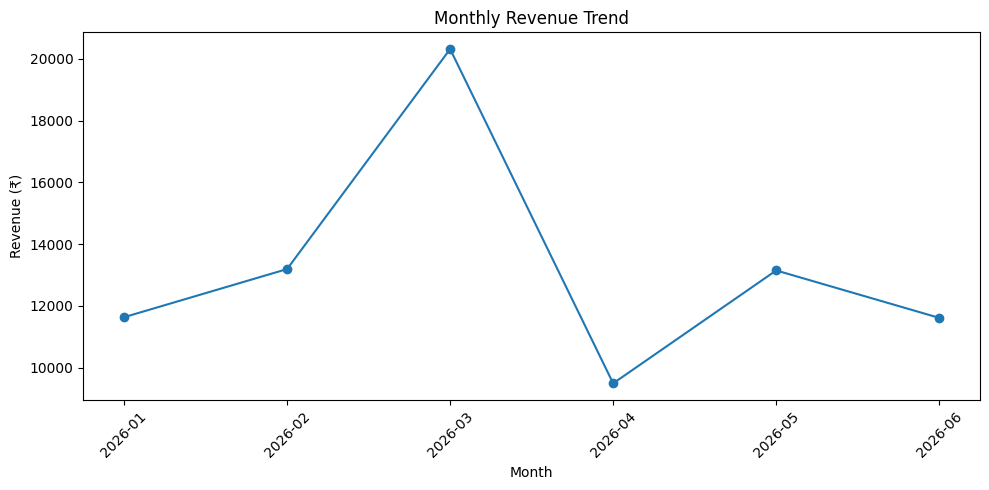

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("monthly_revenue.png", dpi=300)
plt.show()

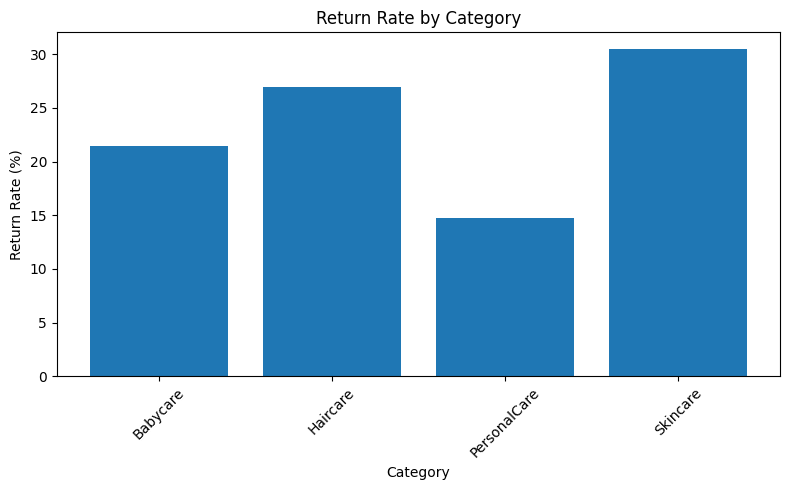

In [ ]:
return_rate = merged_data.groupby("category")["returned"].mean().reset_index()

return_rate["return_rate"] = return_rate["returned"] * 100

plt.figure(figsize=(8, 5))

plt.bar(
    return_rate["category"],
    return_rate["return_rate"]
)

plt.title("Return Rate by Category")
plt.xlabel("Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("return_rate.png", dpi=300)
plt.show()

In [ ]:
correlation_data = merged_data[
    ["quantity", "discount_pct", "rating", "revenue"]
].corr()

print("Correlation Matrix:")
print(correlation_data.round(2))

Correlation Matrix:
              quantity  discount_pct  rating  revenue
quantity          1.00         -0.08    0.08     0.75
discount_pct     -0.08          1.00    0.02    -0.22
rating            0.08          0.02    1.00     0.08
revenue           0.75         -0.22    0.08     1.00


In [ ]:
discount_analysis = merged_data.groupby("discount_pct").agg(
    orders=("order_id", "count"),
    return_rate=("returned", "mean"),
    revenue=("revenue", "sum")
).reset_index()

discount_analysis["return_rate"] = (
    discount_analysis["return_rate"] * 100
).round(2)

discount_analysis["revenue"] = discount_analysis["revenue"].round(2)

print(discount_analysis)

   discount_pct  orders  return_rate  revenue
0           0.0      36        27.78  20952.0
1          10.0      39        25.64  18138.6
2          20.0      40        32.50  17448.8
3          30.0      58        17.24  22873.9


In [ ]:
merged_data.to_csv("cleaned_mamaearth_data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", len(merged_data))
print("Columns:", len(merged_data.columns))

Cleaned dataset saved successfully!
Rows: 173
Columns: 19


In [ ]:
print("Final dataset shape:", merged_data.shape)

print("\nMissing values:")
print(merged_data.isnull().sum())

print("\nDuplicate rows:", merged_data.duplicated().sum())

print("\nPayment methods:")
print(merged_data["payment_method"].value_counts())

Final dataset shape: (173, 19)

Missing values:
order_id              0
customer_id           0
product_id            0
order_date            0
quantity              0
discount_pct          0
payment_method        0
rating                0
returned              0
name                  0
city                  0
city_tier             0
signup_date           0
acquisition_source    0
product_name          0
category              0
price                 0
revenue               0
month                 0
dtype: int64

Duplicate rows: 0

Payment methods:
payment_method
CARD    68
UPI     53
COD     52
Name: count, dtype: int64


In [ ]:
print("===== FINAL PROJECT FINDINGS =====")

print("Total Orders:", len(merged_data))
print("Total Customers:", merged_data["customer_id"].nunique())
print("Total Revenue: ₹", round(merged_data["revenue"].sum(), 2))
print("Average Order Value: ₹", round(merged_data["revenue"].mean(), 2))
print("Overall Return Rate:", round(merged_data["returned"].mean() * 100, 2), "%")

highest_category = category_analysis.loc[
    category_analysis["revenue"].idxmax()
]

highest_return_category = category_analysis.loc[
    category_analysis["return_rate"].idxmax()
]

highest_revenue_product = product_analysis.loc[
    product_analysis["revenue"].idxmax()
]

highest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmin()
]

print("\nHighest Revenue Category:",
      highest_category["category"],
      "₹", highest_category["revenue"])

print("Highest Return Rate Category:",
      highest_return_category["category"],
      highest_return_category["return_rate"], "%")

print("Highest Revenue Product:",
      highest_revenue_product["product_name"],
      "₹", highest_revenue_product["revenue"])

print("Highest Revenue Month:",
      highest_month["month"],
      "₹", highest_month["revenue"])

print("Lowest Revenue Month:",
      lowest_month["month"],
      "₹", lowest_month["revenue"])

===== FINAL PROJECT FINDINGS =====
Total Orders: 173
Total Customers: 44
Total Revenue: ₹ 79413.3
Average Order Value: ₹ 459.04
Overall Return Rate: 24.86 %

Highest Revenue Category: Haircare ₹ 33228.2
Highest Return Rate Category: Skincare 30.51 %
Highest Revenue Product: Argan Hair Mask ₹ 11141.4
Highest Revenue Month: 2026-03 ₹ 20318.9
Lowest Revenue Month: 2026-04 ₹ 9495.3


In [ ]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'sample_data']


In [ ]:
import os

os.makedirs("data", exist_ok=True)

customers_data = """customer_id,name,city,city_tier,signup_date,acquisition_source
C001,Aarav,Mumbai,1,2026-01-07,Organic
C002,Vivaan,Delhi,1,2026-02-27,Referral
C003,Aditi,Mumbai,1,2026-06-23,Organic
C004,Ananya,Lucknow,2,2026-01-23,Organic
C005,Ishaan,Mumbai,1,2026-01-08,Referral
C006,Diya,Delhi,1,2026-05-10,Organic
C007,Kabir,Lucknow,2,2026-02-20,Organic
C008,Meera,Lucknow,2,2026-04-18,Ad
C009,Rohan,Lucknow,2,2026-03-13,Social
C010,Sara,Mumbai,1,2026-02-10,Organic
C011,Arjun,Bangalore,1,2026-03-13,Referral
C012,Priya,Bangalore,1,2026-01-27,Referral
C013,Karan,Mumbai,1,2026-04-02,Social
C014,Neha,Lucknow,2,2026-03-09,Social
C015,Yash,Jaipur,2,2026-05-18,Referral
C016,Pooja,Jaipur,2,2026-01-21,Organic
C017,Rahul,Lucknow,2,2026-04-03,Organic
C018,Simran,Mumbai,1,2026-01-12,Organic
C019,Dev,Bangalore,1,2026-01-21,Social
C020,Tara,Mumbai,1,2026-04-08,Ad
C021,Aryan,Bangalore,1,2026-02-11,Ad
C022,Kavya,Delhi,1,2026-06-21,Ad
C023,Nikhil,Mumbai,1,2026-06-05,Organic
C024,Riya,Lucknow,2,2026-03-04,Referral
C025,Varun,Jaipur,2,2026-03-11,Social
C026,Isha,Lucknow,2,2026-02-26,Organic
C027,Manav,Mumbai,1,2026-02-28,Social
C028,Shreya,Bangalore,1,2026-04-13,Ad
C029,Tanish,Delhi,1,2026-05-26,Social
C030,Anika,Bangalore,1,2026-02-24,Organic
C031,Aditya,Jaipur,2,2026-06-14,Ad
C032,Naina,Bangalore,1,2026-02-05,Ad
C033,Siddharth,Lucknow,2,2026-05-18,Ad
C034,Zara,Lucknow,2,2026-04-20,Social
C035,Krishna,Jaipur,2,2026-04-03,Ad
C036,Aisha,Delhi,1,2026-05-11,Ad
C037,Rudra,Mumbai,1,2026-01-29,Referral
C038,Myra,Delhi,1,2026-06-24,Ad
C039,Om,Mumbai,1,2026-04-09,Ad
C040,Vanya,Jaipur,2,2026-05-16,Ad
C041,Ayaan,Lucknow,2,2026-01-03,Organic
C042,Sanya,Mumbai,1,2026-06-24,Social
C043,Reyansh,Bangalore,1,2026-06-14,Ad
C044,Aria,Bangalore,1,2026-04-22,Referral
C045,Vihaan,Mumbai,1,2026-03-09,Social"""

with open("data/customers.csv", "w") as f:
    f.write(customers_data)

print("customers.csv created successfully!")

customers.csv created successfully!


In [ ]:
products_data = """product_id,product_name,category,price
P01,Onion Hair Oil,Haircare,349
P02,Onion Shampoo,Haircare,399
P03,Argan Hair Mask,Haircare,599
P04,Anti-Hairfall Serum,Haircare,649
P05,Rice Water Conditioner,Haircare,349
P06,Vitamin C Face Wash,Skincare,249
P07,Vitamin C Serum,Skincare,699
P08,Tea Tree Face Wash,Skincare,229
P09,Ubtan Face Mask,Skincare,299
P10,Rice Sunscreen SPF50,Skincare,449
P11,Milky Soft Baby Lotion,Babycare,299
P12,Baby Shampoo,Babycare,249
P13,Baby Massage Oil,Babycare,279
P14,Charcoal Deodorant,PersonalCare,199
P15,Tea Tree Body Wash,PersonalCare,349
P16,Aloe Vera Gel,PersonalCare,199"""

with open("data/products.csv", "w") as f:
    f.write(products_data)

print("products.csv created successfully!")

products.csv created successfully!


In [ ]:
orders_data = """order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,rating,returned
O0001,C012,P04,2026-03-18,2,10,upi,2,0
O0002,C024,P06,2026-05-16,1,30,UPI,1,0
O0003,C008,P12,2026-03-20,2,0,COD,1,1
O0004,C032,P03,2026-05-17,3,30,UPI,5,0
O0005,C011,P09,2026-06-05,1,10,Card,3,0
O0006,C026,P12,2026-05-13,1,0,Card,3,0
O0007,C002,P08,2026-01-02,1,10,COD,1,0
O0008,C003,P11,2026-03-02,1,10,COD,,0
O0009,C037,P16,2026-05-02,1,0,UPI,4,0
O0010,C023,P14,2026-01-14,1,0,Card,1,0
O0011,C026,P11,2026-01-28,25,0,COD,2,1
O0012,C028,P06,2026-03-05,1,0,UPI,1,1
O0013,C042,P01,2026-03-02,3,,COD,4,0
O0014,C004,P06,2026-04-10,1,30,cod,3,0
O0015,C028,P16,2026-03-17,1,,COD,3,1
O0016,C004,P02,2026-05-09,1,0,UPI,5,0
O0017,C006,P06,2026-01-18,1,,Card,5,0
O0018,C016,P02,2026-04-18,2,20,CARD,3,0
O0019,C014,P11,2026-04-12,1,30,COD,3,0
O0020,C005,P01,2026-05-25,1,10,UPI,5,1
O0021,C017,P05,2026-01-18,3,10,UPI,,0
O0022,C035,P10,2026-06-17,2,20,Card,1,0
O0023,C009,P09,2026-01-28,1,20,Card,5,0
O0024,C014,P11,2026-06-12,1,20,UPI,1,0
O0025,C006,P14,2026-01-12,2,20,COD,2,0
O0026,C029,P14,2026-01-29,1,10,COD,5,0
O0027,C003,P12,2026-02-07,1,20,card,1,1
O0028,C023,P07,2026-06-20,2,30,COD,5,0
O0029,C010,P08,2026-02-15,2,20,UPI,4,1
O0030,C043,P08,2026-06-29,1,,COD,2,0
O0031,C013,P15,2026-02-28,1,30,COD,3,0
O0032,C018,P03,2026-03-13,3,,Card,1,0
O0033,C008,P09,2026-03-09,1,20,COD,3,0
O0034,C028,P04,2026-05-28,1,30,COD,1,1
O0035,C034,P07,2026-01-18,1,20,UPI,1,0
O0036,C020,P10,2026-03-25,2,,Card,2,0
O0037,C027,P13,2026-02-14,2,0,Card,3,0
O0038,C019,P07,2026-05-29,1,30,Card,4,0
O0039,C044,P07,2026-02-13,1,20,Card,1,0
O0040,C016,P10,2026-02-20,1,30,cod,5,1
O0041,C005,P15,2026-06-11,1,30,Card,4,0
O0042,C026,P08,2026-06-26,1,0,COD,4,0
O0043,C015,P06,2026-06-28,2,10,Card,1,1
O0044,C030,P05,2026-06-20,2,20,Card,4,0
O0045,C040,P14,2026-05-21,2,30,Card,4,0
O0046,C017,P08,2026-03-12,2,10,UPI,3,0
O0047,C029,P03,2026-03-02,2,0,COD,2,1
O0048,C010,P08,2026-02-09,1,30,Card,3,1
O0049,C035,P15,2026-02-22,1,0,UPI,5,0
O0050,C025,P16,2026-04-01,1,30,COD,5,1
O0051,C035,P08,2026-03-11,1,20,Card,4,1
O0052,C011,P15,2026-06-09,3,0,CARD,1,0
O0053,C042,P14,2026-04-29,1,20,cod,,1
O0054,C030,P11,2026-04-08,1,30,COD,,0
O0055,C006,P16,2026-05-19,1,10,COD,1,0
O0056,C042,P02,2026-03-05,2,10,COD,2,1
O0057,C009,P16,2026-05-25,2,20,UPI,3,0
O0058,C011,P04,2026-02-11,2,0,UPI,3,0
O0059,C037,P13,2026-02-20,1,10,COD,1,0
O0060,C020,P04,2026-05-25,2,30,UPI,3,0
O0061,C005,P11,2026-04-18,1,20,UPI,4,0
O0062,C010,P14,2026-05-14,1,30,UPI,4,0
O0063,C028,P09,2026-03-04,1,30,UPI,2,1
O0064,C030,P13,2026-05-07,1,10,UPI,3,0
O0065,C017,P11,2026-06-02,1,0,Card,5,0
O0066,C013,P03,2026-04-15,1,30,card,4,0
O0067,C029,P01,2026-02-26,1,20,Card,4,0
O0068,C036,P12,2026-05-21,1,20,Card,3,0
O0069,C017,P08,2026-02-19,1,10,CARD,2,0
O0070,C014,P16,2026-05-31,1,20,UPI,1,0
O0071,C013,P10,2026-02-15,1,10,Card,3,0
O0072,C003,P02,2026-06-28,1,30,UPI,1,0
O0073,C001,P10,2026-04-23,1,20,Card,,0
O0074,C008,P03,2026-01-19,1,10,Card,2,0
O0075,C037,P10,2026-03-05,1,10,COD,5,0
O0076,C025,P15,2026-03-18,3,20,UPI,5,0
O0077,C040,P02,2026-01-26,2,10,UPI,3,0
O0078,C043,P03,2026-02-14,1,30,Card,4,0
O0079,C039,P16,2026-03-01,1,30,cod,,1
O0080,C044,P08,2026-06-10,3,,Card,4,0
O0081,C008,P08,2026-03-10,2,10,UPI,3,1
O0082,C039,P10,2026-04-30,1,,Card,5,0
O0083,C035,P16,2026-06-03,1,20,COD,5,0
O0084,C017,P01,2026-06-22,1,0,UPI,3,0
O0085,C037,P02,2026-02-14,2,,Card,2,0
O0086,C038,P14,2026-05-06,2,30,UPI,3,0
O0087,C021,P04,2026-03-26,2,30,Card,5,0
O0088,C003,P15,2026-03-06,1,30,Card,,0
O0089,C001,P15,2026-02-18,1,30,Card,4,0
O0090,C004,P07,2026-02-03,1,30,UPI,1,0
O0091,C002,P08,2026-03-21,2,0,Card,2,0
O0092,C008,P15,2026-06-15,3,20,upi,5,0
O0093,C018,P14,2026-05-01,2,30,COD,2,0
O0094,C039,P05,2026-03-12,2,20,UPI,5,0
O0095,C018,P01,2026-03-18,1,30,UPI,,0
O0096,C029,P16,2026-05-22,1,20,UPI,2,0
O0097,C016,P13,2026-04-16,1,30,COD,4,0
O0098,C043,P05,2026-01-10,30,0,COD,1,0
O0099,C029,P04,2026-04-27,1,10,COD,1,1
O0100,C031,P09,2026-06-27,1,20,Card,5,1
O0101,C025,P11,2026-05-05,2,0,UPI,2,1
O0102,C041,P10,2026-01-24,3,0,Card,4,1
O0103,C011,P10,2026-01-12,3,20,CARD,3,1
O0104,C028,P05,2026-04-16,1,10,Card,2,0
O0105,C006,P13,2026-03-03,2,10,card,4,0
O0106,C041,P09,2026-06-20,1,20,COD,5,0
O0107,C011,P03,2026-03-30,1,30,UPI,3,0
O0108,C030,P10,2026-04-09,1,30,UPI,5,0
O0109,C023,P10,2026-03-17,3,30,COD,3,0
O0110,C001,P02,2026-05-08,3,10,UPI,5,0
O0111,C023,P08,2026-06-08,2,10,COD,1,0
O0112,C041,P02,2026-04-23,1,10,COD,1,1
O0113,C019,P11,2026-02-14,2,20,COD,5,0
O0114,C033,P09,2026-03-07,2,20,UPI,3,0
O0115,C008,P15,2026-02-06,3,30,UPI,5,0
O0116,C024,P03,2026-01-04,2,20,COD,3,1
O0117,C038,P13,2026-04-06,2,0,COD,5,1
O0118,C036,P11,2026-02-26,3,30,card,,0
O0119,C042,P14,2026-01-12,1,30,UPI,1,0
O0120,C007,P08,2026-02-04,2,30,CARD,5,0
O0121,C010,P14,2026-05-06,2,20,Card,1,0
O0122,C024,P07,2026-03-02,1,20,UPI,5,1
O0123,C042,P12,2026-03-12,1,30,COD,1,1
O0124,C043,P07,2026-06-02,2,20,UPI,,1
O0125,C009,P07,2026-05-22,1,10,COD,3,1
O0126,C010,P01,2026-02-07,1,10,UPI,1,0
O0127,C043,P01,2026-04-02,1,20,UPI,1,0
O0128,C012,P09,2026-04-18,1,30,Card,4,0
O0129,C024,P04,2026-02-26,1,20,UPI,4,1
O0130,C042,P01,2026-05-03,1,0,UPI,4,0
O0131,C029,P03,2026-03-24,2,20,card,5,1
O0132,C041,P11,2026-06-02,1,30,Card,1,0
O0133,C008,P07,2026-02-28,1,30,Card,4,0
O0134,C007,P11,2026-06-20,1,30,COD,,0
O0135,C006,P03,2026-01-25,1,10,Card,5,0
O0136,C004,P11,2026-04-16,2,30,Card,1,0
O0137,C019,P10,2026-05-28,1,30,CARD,2,0
O0138,C007,P12,2026-04-05,2,10,COD,4,1
O0139,C036,P01,2026-06-18,2,10,UPI,3,0
O0140,C020,P11,2026-02-16,1,30,UPI,1,0
O0141,C010,P01,2026-05-16,1,20,COD,2,1
O0142,C024,P10,2026-05-26,2,10,Card,2,0
O0143,C040,P02,2026-03-11,2,30,Card,4,0
O0144,C018,P07,2026-01-30,2,30,card,5,0
O0145,C043,P10,2026-04-12,1,10,UPI,3,1
O0146,C014,P05,2026-03-16,2,30,Card,2,1
O0147,C009,P13,2026-02-28,1,20,Card,1,0
O0148,C026,P02,2026-04-28,1,30,UPI,5,0
O0149,C026,P14,2026-04-14,1,30,COD,,1
O0150,C006,P14,2026-03-04,2,0,Card,4,0
O0151,C020,P11,2026-02-13,1,10,COD,3,0
O0152,C023,P05,2026-02-07,1,,COD,1,1
O0153,C012,P16,2026-05-25,1,20,UPI,3,0
O0154,C010,P15,2026-04-24,1,0,CARD,3,0
O0155,C033,P03,2026-04-26,1,20,COD,1,1
O0156,C042,P03,2026-05-10,2,,Card,4,0
O0157,C037,P07,2026-05-02,1,30,card,1,0
O0158,C022,P03,2026-02-14,1,30,COD,5,0
O0159,C034,P06,2026-03-14,1,0,Card,3,0
O0160,C005,P11,2026-06-23,1,10,Card,3,0
O0161,C006,P05,2026-03-21,3,30,UPI,2,0
O0162,C039,P03,2026-04-07,1,10,Card,5,0
O0163,C006,P14,2026-01-05,1,10,Card,,0
O0164,C032,P07,2026-02-05,1,0,COD,,1
O0165,C035,P02,2026-06-08,2,10,COD,2,1
O0166,C040,P06,2026-01-12,2,10,Card,4,0
O0167,C040,P10,2026-04-25,2,30,COD,2,1
O0168,C024,P15,2026-03-14,1,30,UPI,,0
O0169,C013,P05,2026-01-14,2,,Card,5,0
O0170,C008,P10,2026-02-11,1,10,cod,4,0
O0171,C006,P08,2026-03-31,2,30,UPI,5,0
O0172,C024,P08,2026-01-21,1,0,Card,3,1
O0173,C010,P05,2026-05-01,1,30,Card,4,0
O0174,C040,P01,2026-01-05,3,30,COD,1,0
O0175,C019,P08,2026-01-13,1,30,COD,1,0
O0176,C032,P03,2026-05-17,3,30,UPI,5,0
O0177,C005,P15,2026-06-11,1,30,Card,4,0
O0178,C008,P08,2026-03-10,2,10,UPI,3,1
O0179,C010,P14,2026-05-06,2,20,Card,1,0
O0180,C020,P11,2026-02-13,1,10,COD,3,0
"""

with open("data/orders.csv", "w") as f:
    f.write(orders_data)

print("orders.csv created successfully!")

orders.csv created successfully!


In [ ]:
import pandas as pd

orders_check = pd.read_csv("data/orders.csv")

print("Orders:", orders_check.shape)
print(orders_check.head())

Orders: (180, 9)
  order_id customer_id product_id  order_date  quantity  discount_pct  \
0    O0001        C012        P04  2026-03-18         2          10.0   
1    O0002        C024        P06  2026-05-16         1          30.0   
2    O0003        C008        P12  2026-03-20         2           0.0   
3    O0004        C032        P03  2026-05-17         3          30.0   
4    O0005        C011        P09  2026-06-05         1          10.0   

  payment_method  rating  returned  
0            upi     2.0         0  
1            UPI     1.0         0  
2            COD     1.0         1  
3            UPI     5.0         0  
4           Card     3.0         0  


In [ ]:
import pandas as pd

customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)


Customers: (45, 6)
Products: (16, 4)
Orders: (180, 9)


In [ ]:
# Load all datasets

customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)

print("\nMissing values in orders:")
print(orders.isnull().sum())

Customers: (45, 6)
Products: (16, 4)
Orders: (180, 9)

Missing values in orders:
order_id           0
customer_id        0
product_id         0
order_date         0
quantity           0
discount_pct      12
payment_method     0
rating            15
returned           0
dtype: int64


In [ ]:
# Make a copy so raw data remains unchanged
clean_orders = orders.copy()

# 1. Remove duplicate orders based on natural key
clean_orders = clean_orders.drop_duplicates(
    subset=["customer_id", "product_id", "order_date",
            "quantity", "discount_pct", "payment_method",
            "rating", "returned"],
    keep="first"
)

# 2. Standardize payment method
clean_orders["payment_method"] = (
    clean_orders["payment_method"].str.upper()
)

# 3. Fill missing discount with 0
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)

# 4. Fill missing rating with median
clean_orders["rating"] = clean_orders["rating"].fillna(
    clean_orders["rating"].median()
)

# 5. Remove quantity outliers
clean_orders = clean_orders[clean_orders["quantity"] <= 3]

# 6. Convert order date to datetime
clean_orders["order_date"] = pd.to_datetime(clean_orders["order_date"])

print("Cleaned data shape:", clean_orders.shape)
print("\nMissing values:")
print(clean_orders.isnull().sum())

Cleaned data shape: (173, 9)

Missing values:
order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
discount_pct      0
payment_method    0
rating            0
returned          0
dtype: int64


In [ ]:
# Merge orders with customer and product data

merged_data = clean_orders.merge(
    customers,
    on="customer_id",
    how="left"
)

merged_data = merged_data.merge(
    products,
    on="product_id",
    how="left"
)

# Calculate revenue after discount
merged_data["revenue"] = (
    merged_data["price"]
    * merged_data["quantity"]
    * (1 - merged_data["discount_pct"] / 100)
)

# Create month column
merged_data["month"] = merged_data["order_date"].dt.to_period("M").astype(str)

print("Merged data shape:", merged_data.shape)
print("\nTotal Revenue: ₹", round(merged_data["revenue"].sum(), 2))
print("\nColumns:")
print(merged_data.columns.tolist())

Merged data shape: (173, 19)

Total Revenue: ₹ 79413.3

Columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'discount_pct', 'payment_method', 'rating', 'returned', 'name', 'city', 'city_tier', 'signup_date', 'acquisition_source', 'product_name', 'category', 'price', 'revenue', 'month']


In [ ]:
print("===== FINAL PROJECT FINDINGS =====")

print("Total Orders:", len(merged_data))
print("Total Customers:", merged_data["customer_id"].nunique())
print("Total Products Sold:", merged_data["product_id"].nunique())
print("Total Revenue: ₹", round(merged_data["revenue"].sum(), 2))
print("Average Order Value: ₹", round(merged_data["revenue"].mean(), 2))
print("Overall Return Rate:", round(merged_data["returned"].mean() * 100, 2), "%")

===== FINAL PROJECT FINDINGS =====
Total Orders: 173
Total Customers: 44
Total Products Sold: 16
Total Revenue: ₹ 79413.3
Average Order Value: ₹ 459.04
Overall Return Rate: 24.86 %


In [ ]:
merged_data.to_csv("cleaned_mamaearth_data.csv", index=False)

print("cleaned_mamaearth_data.csv created successfully!")

cleaned_mamaearth_data.csv created successfully!


In [ ]:
category_analysis = merged_data.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    quantity=("quantity", "sum"),
    return_rate=("returned", "mean")
).reset_index()

category_analysis["return_rate"] = (
    category_analysis["return_rate"] * 100
).round(2)

category_analysis["revenue"] = category_analysis["revenue"].round(2)

print(category_analysis)

       category  orders  revenue  quantity  return_rate
0      Babycare      28   9060.9        38        21.43
1      Haircare      52  33228.2        85        26.92
2  PersonalCare      34  10190.4        49        14.71
3      Skincare      59  26933.8        84        30.51


In [ ]:
product_analysis = merged_data.groupby(
    ["product_id", "product_name", "category"]
).agg(
    orders=("order_id", "count"),
    quantity=("quantity", "sum"),
    revenue=("revenue", "sum"),
    return_rate=("returned", "mean")
).reset_index()

product_analysis["return_rate"] = (
    product_analysis["return_rate"] * 100
).round(2)

product_analysis["revenue"] = product_analysis["revenue"].round(2)

product_analysis = product_analysis.sort_values(
    "revenue", ascending=False
)

print(product_analysis.head(10))

   product_id            product_name      category  orders  quantity  \
2         P03         Argan Hair Mask      Haircare      14        22   
9         P10    Rice Sunscreen SPF50      Skincare      16        26   
6         P07         Vitamin C Serum      Skincare      12        15   
1         P02           Onion Shampoo      Haircare      11        19   
3         P04     Anti-Hairfall Serum      Haircare       7        11   
14        P15      Tea Tree Body Wash  PersonalCare      11        19   
7         P08      Tea Tree Face Wash      Skincare      16        25   
4         P05  Rice Water Conditioner      Haircare       9        17   
0         P01          Onion Hair Oil      Haircare      11        16   
10        P11  Milky Soft Baby Lotion      Babycare      15        20   

    revenue  return_rate  
2   11141.4        28.57  
9    9788.2        31.25  
6    8038.5        33.33  
1    6543.6        27.27  
3    5841.0        42.86  
14   5374.6         0.00  
7    49

In [ ]:
monthly_revenue = merged_data.groupby("month").agg(
    revenue=("revenue", "sum"),
    orders=("order_id", "count")
).reset_index()

monthly_revenue["revenue"] = monthly_revenue["revenue"].round(2)

print(monthly_revenue)


     month  revenue  orders
0  2026-01  11637.1      22
1  2026-02  13195.5      31
2  2026-03  20318.9      37
3  2026-04   9495.3      27
4  2026-05  13151.1      31
5  2026-06  11615.4      25


In [ ]:
correlation_data = merged_data[
    ["quantity", "discount_pct", "rating", "revenue"]
].corr()

print("Correlation Matrix:")
print(correlation_data.round(2))

Correlation Matrix:
              quantity  discount_pct  rating  revenue
quantity          1.00         -0.08    0.08     0.75
discount_pct     -0.08          1.00    0.02    -0.22
rating            0.08          0.02    1.00     0.08
revenue           0.75         -0.22    0.08     1.00


In [ ]:
discount_analysis = merged_data.groupby("discount_pct").agg(
    orders=("order_id", "count"),
    return_rate=("returned", "mean"),
    revenue=("revenue", "sum")
).reset_index()

discount_analysis["return_rate"] = (
    discount_analysis["return_rate"] * 100
).round(2)

discount_analysis["revenue"] = (
    discount_analysis["revenue"].round(2)
)

print(discount_analysis)

   discount_pct  orders  return_rate  revenue
0           0.0      36        27.78  20952.0
1          10.0      39        25.64  18138.6
2          20.0      40        32.50  17448.8
3          30.0      58        17.24  22873.9


In [ ]:
print("Final dataset shape:", merged_data.shape)

print("\nMissing values:")
print(merged_data.isnull().sum())

print("\nDuplicate rows:", merged_data.duplicated().sum())

print("\nPayment methods:")
print(merged_data["payment_method"].value_counts())

Final dataset shape: (173, 19)

Missing values:
order_id              0
customer_id           0
product_id            0
order_date            0
quantity              0
discount_pct          0
payment_method        0
rating                0
returned              0
name                  0
city                  0
city_tier             0
signup_date           0
acquisition_source    0
product_name          0
category              0
price                 0
revenue               0
month                 0
dtype: int64

Duplicate rows: 0

Payment methods:
payment_method
CARD    68
UPI     53
COD     52
Name: count, dtype: int64


In [ ]:
highest_category = category_analysis.loc[
    category_analysis["revenue"].idxmax()
]

highest_return_category = category_analysis.loc[
    category_analysis["return_rate"].idxmax()
]

highest_revenue_product = product_analysis.loc[
    product_analysis["revenue"].idxmax()
]

highest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmin()
]

print("===== FINAL PROJECT FINDINGS =====")

print("Total Orders:", len(merged_data))
print("Total Customers:", merged_data["customer_id"].nunique())
print("Total Revenue: ₹", round(merged_data["revenue"].sum(), 2))
print("Average Order Value: ₹", round(merged_data["revenue"].mean(), 2))
print("Overall Return Rate:", round(merged_data["returned"].mean() * 100, 2), "%")

print("\nHighest Revenue Category:",
      highest_category["category"],
      "₹", highest_category["revenue"])

print("Highest Return Rate Category:",
      highest_return_category["category"],
      highest_return_category["return_rate"], "%")

print("Highest Revenue Product:",
      highest_revenue_product["product_name"],
      "₹", highest_revenue_product["revenue"])

print("Highest Revenue Month:",
      highest_month["month"],
      "₹", highest_month["revenue"])

print("Lowest Revenue Month:",
      lowest_month["month"],
      "₹", lowest_month["revenue"])

===== FINAL PROJECT FINDINGS =====
Total Orders: 173
Total Customers: 44
Total Revenue: ₹ 79413.3
Average Order Value: ₹ 459.04
Overall Return Rate: 24.86 %

Highest Revenue Category: Haircare ₹ 33228.2
Highest Return Rate Category: Skincare 30.51 %
Highest Revenue Product: Argan Hair Mask ₹ 11141.4
Highest Revenue Month: 2026-03 ₹ 20318.9
Lowest Revenue Month: 2026-04 ₹ 9495.3


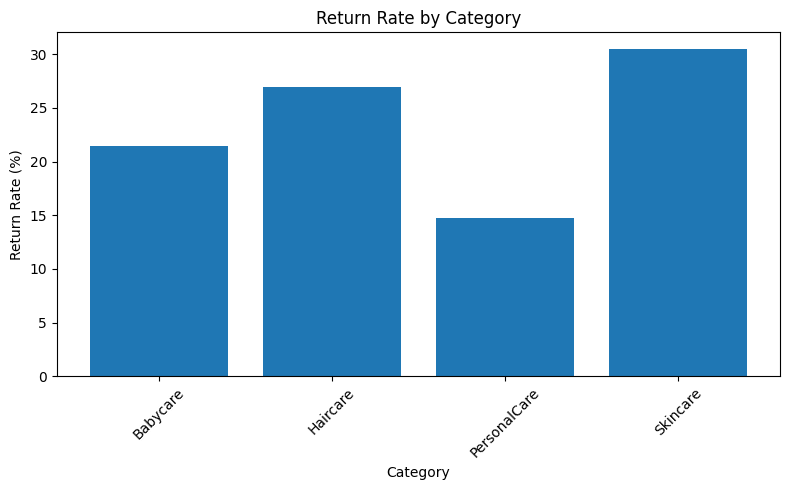

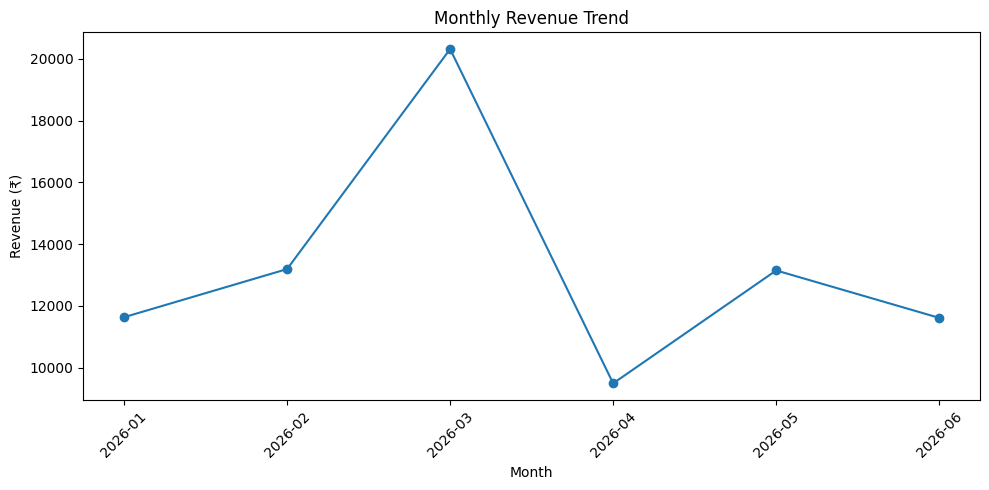

Both charts saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# Chart 1: Return Rate by Category
return_rate = merged_data.groupby("category")["returned"].mean().reset_index()
return_rate["return_rate"] = return_rate["returned"] * 100

plt.figure(figsize=(8, 5))
plt.bar(return_rate["category"], return_rate["return_rate"])
plt.title("Return Rate by Category")
plt.xlabel("Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("return_rate.png", dpi=300)
plt.show()


# Chart 2: Monthly Revenue Trend
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue["month"],
    monthly_revenue["revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_revenue.png", dpi=300)
plt.show()

print("Both charts saved successfully!")

In [ ]:
from google.colab import files

files.download("cleaned_mamaearth_data.csv")
files.download("return_rate.png")
files.download("monthly_revenue.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "mamaearth" in file.lower() or file in [
            "cleaned_mamaearth_data.csv",
            "return_rate.png",
            "monthly_revenue.png"
        ]:
            print(os.path.join(root, file))

/content/drive/MyDrive/Capstone_Guidelines_Mamaearth (2).gdoc
/content/drive/MyDrive/Capstone_Guidelines_Mamaearth (1).gdoc
/content/drive/MyDrive/Capstone_Guidelines_Mamaearth.gdoc
/content/drive/MyDrive/Colab Notebooks/Untitled13Mamaearth_Capstone.ipynb


In [ ]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/Untitled13Mamaearth_Capstone.ipynb"

with open(path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in [
        "cleaned_mamaearth",
        "return_rate",
        "monthly_revenue",
        "findings.json",
        "gemini",
        "sqlite"
    ]):
        print(f"\n--- Cell {i + 1} ---")
        print(source[:1200])


--- Cell 22 ---
category_analysis = merged_data.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    quantity_sold=("quantity", "sum"),
    return_rate=("returned", "mean")
).reset_index()

category_analysis["return_rate"] = category_analysis["return_rate"] * 100
category_analysis["revenue"] = category_analysis["revenue"].round(2)
category_analysis["return_rate"] = category_analysis["return_rate"].round(2)

print(category_analysis.sort_values("revenue", ascending=False))

--- Cell 23 ---
product_analysis = merged_data.groupby(
    ["product_id", "product_name"]
).agg(
    orders=("order_id", "count"),
    quantity_sold=("quantity", "sum"),
    revenue=("revenue", "sum"),
    return_rate=("returned", "mean")
).reset_index()

product_analysis["return_rate"] = (
    product_analysis["return_rate"] * 100
).round(2)

product_analysis["revenue"] = product_analysis["revenue"].round(2)

top_products = product_analysis.sort_values(
    "revenue", ascen

In [ ]:
for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in [
        "drop_duplicates",
        "median",
        "iqr",
        "payment_method",
        "city_tier",
        "corr()",
        "findings.json",
        "generate_narrative"
    ]):
        print(f"\n--- Cell {i + 1} ---")
        print(source[:700])


--- Cell 3 ---
customers = """customer_id,name,city,city_tier,signup_date,acquisition_source
C001,Aarav,Mumbai,1,2026-01-07,Organic
C002,Vivaan,Delhi,1,2026-02-27,Referral
C003,Aditi,Mumbai,1,2026-06-23,Organic
C004,Ananya,Lucknow,2,2026-01-23,Organic
C005,Ishaan,Mumbai,1,2026-01-08,Referral
C006,Diya,Delhi,1,2026-05-10,Organic
C007,Kabir,Lucknow,2,2026-02-20,Organic
C008,Meera,Lucknow,2,2026-04-18,Ad
C009,Rohan,Lucknow,2,2026-03-13,Social
C010,Sara,Mumbai,1,2026-02-10,Organic
C011,Arjun,Bangalore,1,2026-03-13,Referral
C012,Priya,Bangalore,1,2026-01-27,Referral
C013,Karan,Mumbai,1,2026-04-02,Social
C014,Neha,Lucknow,2,2026-03-09,Social
C015,Yash,Jaipur,2,2026-05-18,Referral
C016,Pooja,Jaipur,2,2026-01-21,O

--- Cell 6 ---
orders_data = """order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,rating,returned
O0001,C012,P04,2026-03-18,2,10,upi,2,0
O0002,C024,P06,2026-05-16,1,30,UPI,1,0
O0003,C008,P12,2026-03-20,2,0,COD,1,1
O0004,C032,P03,2026-05-17,3,30,UPI,5,0

In [ ]:
source = "".join(notebook["cells"][38].get("source", []))
print(source)

# Make a copy so raw data remains unchanged
clean_orders = orders.copy()

# 1. Remove duplicate orders based on natural key
clean_orders = clean_orders.drop_duplicates(
    subset=["customer_id", "product_id", "order_date",
            "quantity", "discount_pct", "payment_method",
            "rating", "returned"],
    keep="first"
)

# 2. Standardize payment method
clean_orders["payment_method"] = (
    clean_orders["payment_method"].str.upper()
)

# 3. Fill missing discount with 0
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)

# 4. Fill missing rating with median
clean_orders["rating"] = clean_orders["rating"].fillna(
    clean_orders["rating"].median()
)

# 5. Remove quantity outliers
clean_orders = clean_orders[clean_orders["quantity"] <= 3]

# 6. Convert order date to datetime
clean_orders["order_date"] = pd.to_datetime(clean_orders["order_date"])

print("Cleaned data shape:", clean_orders.shape)
print("\nMissing values:")
print(clean_orders.isnull().sum())

In [ ]:
for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if 'clean_orders = clean_orders[clean_orders["quantity"] <= 3]' in source:
        print("Cell number:", i + 1)
        print(source)

Cell number: 39
# Make a copy so raw data remains unchanged
clean_orders = orders.copy()

# 1. Remove duplicate orders based on natural key
clean_orders = clean_orders.drop_duplicates(
    subset=["customer_id", "product_id", "order_date",
            "quantity", "discount_pct", "payment_method",
            "rating", "returned"],
    keep="first"
)

# 2. Standardize payment method
clean_orders["payment_method"] = (
    clean_orders["payment_method"].str.upper()
)

# 3. Fill missing discount with 0
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)

# 4. Fill missing rating with median
clean_orders["rating"] = clean_orders["rating"].fillna(
    clean_orders["rating"].median()
)

# 5. Remove quantity outliers
clean_orders = clean_orders[clean_orders["quantity"] <= 3]

# 6. Convert order date to datetime
clean_orders["order_date"] = pd.to_datetime(clean_orders["order_date"])

print("Cleaned data shape:", clean_orders.shape)
print("\nMissing values:")
print(clean_orders

In [ ]:
source = "".join(notebook["cells"][38].get("source", []))

source = source.replace(
    'clean_orders = clean_orders[clean_orders["quantity"] <= 3]',
    '''# 5. Detect quantity outliers using IQR
Q1 = clean_orders["quantity"].quantile(0.25)
Q3 = clean_orders["quantity"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

clean_orders["quantity_outlier"] = (
    (clean_orders["quantity"] < lower_bound) |
    (clean_orders["quantity"] > upper_bound)
)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Outlier orders:")
print(clean_orders.loc[
    clean_orders["quantity_outlier"],
    ["order_id", "quantity"]
])'''
)

notebook["cells"][38]["source"] = source.splitlines(keepends=True)

with open(path, "w", encoding="utf-8") as f:
    json.dump(notebook, f, ensure_ascii=False, indent=2)

print("Cell 39 updated in the saved notebook.")

Cell 39 updated in the saved notebook.


In [ ]:
source = "".join(notebook["cells"][38].get("source", []))
print(source)

# Make a copy so raw data remains unchanged
clean_orders = orders.copy()

# 1. Remove duplicate orders based on natural key
clean_orders = clean_orders.drop_duplicates(
    subset=["customer_id", "product_id", "order_date",
            "quantity", "discount_pct", "payment_method",
            "rating", "returned"],
    keep="first"
)

# 2. Standardize payment method
clean_orders["payment_method"] = (
    clean_orders["payment_method"].str.upper()
)

# 3. Fill missing discount with 0
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)

# 4. Fill missing rating with median
clean_orders["rating"] = clean_orders["rating"].fillna(
    clean_orders["rating"].median()
)

# 5. Remove quantity outliers
# 5. Detect quantity outliers using IQR
Q1 = clean_orders["quantity"].quantile(0.25)
Q3 = clean_orders["quantity"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

clean_orders["quantity_outlier"] = (
    (clean_orders["quantity"] < lower_

In [ ]:
from IPython.display import display, Markdown
print("Code update verified. Now open Cell 39 in the notebook and run it.")

Code update verified. Now open Cell 39 in the notebook and run it.


In [13]:
clean_orders = orders.copy()

clean_orders = clean_orders.drop_duplicates(
    subset=["customer_id", "product_id", "order_date",
            "quantity", "discount_pct", "payment_method",
            "rating", "returned"],
    keep="first"
)

clean_orders["payment_method"] = clean_orders["payment_method"].str.strip().str.upper()
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)
clean_orders["rating"] = clean_orders["rating"].fillna(clean_orders["rating"].median())
clean_orders["order_date"] = pd.to_datetime(clean_orders["order_date"])

Q1 = clean_orders["quantity"].quantile(0.25)
Q3 = clean_orders["quantity"].quantile(0.75)
IQR = Q3 - Q1

NameError: name 'orders' is not defined

In [14]:
print([name for name in globals() if name in ["customers", "products", "orders", "orders_data", "clean_orders"]])

[]


In [15]:
for i, cell in enumerate(notebook["cells"][:12]):
    source = "".join(cell.get("source", []))
    if "orders" in source.lower():
        print(f"\n--- Cell {i+1} ---")
        print(source[:1000])


--- Cell 6 ---
orders_data = """order_id,customer_id,product_id,order_date,quantity,discount_pct,payment_method,rating,returned
O0001,C012,P04,2026-03-18,2,10,upi,2,0
O0002,C024,P06,2026-05-16,1,30,UPI,1,0
O0003,C008,P12,2026-03-20,2,0,COD,1,1
O0004,C032,P03,2026-05-17,3,30,UPI,5,0
O0005,C011,P09,2026-06-05,1,10,Card,3,0
O0006,C026,P12,2026-05-13,1,0,Card,3,0
O0007,C002,P08,2026-01-02,1,10,COD,1,0
O0008,C003,P11,2026-03-02,1,10,COD,,0
O0009,C037,P16,2026-05-02,1,0,UPI,4,0
O0010,C023,P14,2026-01-14,1,0,Card,1,0
O0011,C026,P11,2026-01-28,25,0,COD,2,1
O0012,C028,P06,2026-03-05,1,0,UPI,1,1
O0013,C042,P01,2026-03-02,3,,COD,4,0
O0014,C004,P06,2026-04-10,1,30,cod,3,0
O0015,C028,P16,2026-03-17,1,,COD,3,1
O0016,C004,P02,2026-05-09,1,0,UPI,5,0
O0017,C006,P06,2026-01-18,1,,Card,5,0
O0018,C016,P02,2026-04-18,2,20,CARD,3,0
O0019,C014,P11,2026-04-12,1,30,COD,3,0
O0020,C005,P01,2026-05-25,1,10,UPI,5,1
O0021,C017,P05,2026-01-18,3,10,UPI,,0
O0022,C035,P10,2026-06-17,2,20,Card,1,0
O0023,C009,P09,2026-0

In [16]:
import os

os.makedirs("data", exist_ok=True)

with open("data/orders.csv", "w") as f:
    f.write(orders_data)

orders = pd.read_csv("data/orders.csv")

print("Orders loaded:", orders.shape)

NameError: name 'orders_data' is not defined

In [17]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/Untitled13Mamaearth_Capstone.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Notebook loaded. Total cells:", len(nb["cells"]))

Notebook loaded. Total cells: 65


In [18]:
import pandas as pd
from io import StringIO

# Load original orders data directly from the saved notebook
orders_source = "".join(nb["cells"][5].get("source", []))
exec(orders_source)

orders = pd.read_csv(StringIO(orders_data))

# Clean the data
clean_orders = orders.copy()

natural_key = [
    "customer_id", "product_id", "order_date", "quantity",
    "discount_pct", "payment_method", "rating", "returned"
]
clean_orders = clean_orders.drop_duplicates(
    subset=natural_key, keep="first"
)

clean_orders["payment_method"] = (
    clean_orders["payment_method"].str.strip().str.upper()
)
clean_orders["discount_pct"] = clean_orders["discount_pct"].fillna(0)
clean_orders["rating"] = clean_orders["rating"].fillna(
    clean_orders["rating"].median()
)
clean_orders["order_date"] = pd.to_datetime(clean_orders["order_date"])

# Detect outliers using IQR without deleting them
Q1 = clean_orders["quantity"].quantile(0.25)
Q3 = clean_orders["quantity"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

clean_orders["quantity_outlier"] = (
    (clean_orders["quantity"] < lower_bound) |
    (clean_orders["quantity"] > upper_bound)
)

print("Original orders:", orders.shape)
print("Cleaned orders:", clean_orders.shape)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Outlier orders:")
print(clean_orders.loc[
    clean_orders["quantity_outlier"], ["order_id", "quantity"]
])
print("Cleaning complete!")

Original orders: (180, 9)
Cleaned orders: (175, 10)
Lower bound: -0.5
Upper bound: 3.5
Outlier orders:
   order_id  quantity
10    O0011        25
97    O0098        30
Cleaning complete!


In [19]:
clean_orders.to_csv("cleaned_mamaearth_data.csv", index=False)

print("Cleaned data saved successfully!")
print("Rows:", len(clean_orders))
print("Columns:", len(clean_orders.columns))

Cleaned data saved successfully!
Rows: 175
Columns: 10


In [20]:
from google.colab import files
files.download("cleaned_mamaearth_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import pandas as pd
from io import StringIO

# Load customers and products data from the saved notebook
for cell in nb["cells"]:
    source = "".join(cell.get("source", []))
    if "customers_data =" in source or "products_data =" in source:
        exec(source)

customers = pd.read_csv(StringIO(customers_data))
products = pd.read_csv(StringIO(products_data))

print("Customers loaded:", customers.shape)
print("Products loaded:", products.shape)
print("Data loaded successfully!")

customers.csv created successfully!
products.csv created successfully!
Customers loaded: (45, 6)
Products loaded: (16, 4)
Data loaded successfully!


In [22]:
# Merge orders with customer details
merged_data = clean_orders.merge(
    customers, on="customer_id", how="left"
)

# Add product details
merged_data = merged_data.merge(
    products, on="product_id", how="left"
)

# Calculate sales after discount
merged_data["revenue"] = (
    merged_data["price"] * merged_data["quantity"] *
    (1 - merged_data["discount_pct"] / 100)
)

print("Merged data shape:", merged_data.shape)
print("Missing customer details:", merged_data["name"].isna().sum())
print("Missing product details:", merged_data["product_name"].isna().sum())
print("\nSample data:")
print(merged_data[[
    "order_id", "customer_id", "product_name",
    "category", "quantity", "revenue"
]].head())

Merged data shape: (175, 19)
Missing customer details: 0
Missing product details: 0

Sample data:
  order_id customer_id         product_name  category  quantity  revenue
0    O0001        C012  Anti-Hairfall Serum  Haircare         2   1168.2
1    O0002        C024  Vitamin C Face Wash  Skincare         1    174.3
2    O0003        C008         Baby Shampoo  Babycare         2    498.0
3    O0004        C032      Argan Hair Mask  Haircare         3   1257.9
4    O0005        C011      Ubtan Face Mask  Skincare         1    269.1


In [23]:
category_analysis = merged_data.groupby("category").agg(
    total_orders=("order_id", "nunique"),
    units_sold=("quantity", "sum"),
    total_revenue=("revenue", "sum"),
    return_rate=("returned", "mean")
).reset_index()

category_analysis["return_rate"] = (
    category_analysis["return_rate"] * 100
).round(2)

category_analysis["total_revenue"] = (
    category_analysis["total_revenue"].round(2)
)

print(category_analysis.to_string(index=False))

    category  total_orders  units_sold  total_revenue  return_rate
    Babycare            29          63        16535.9        24.14
    Haircare            53         115        43698.2        26.42
PersonalCare            34          49        10190.4        14.71
    Skincare            59          84        26933.8        30.51


In [24]:
merged_data["month"] = merged_data["order_date"].dt.to_period("M").astype(str)

monthly_revenue = merged_data.groupby("month").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("revenue", "sum")
).reset_index()

monthly_revenue["total_revenue"] = monthly_revenue["total_revenue"].round(2)

print(monthly_revenue.to_string(index=False))

  month  total_orders  total_revenue
2026-01            24        29582.1
2026-02            31        13195.5
2026-03            37        20318.9
2026-04            27         9495.3
2026-05            31        13151.1
2026-06            25        11615.4


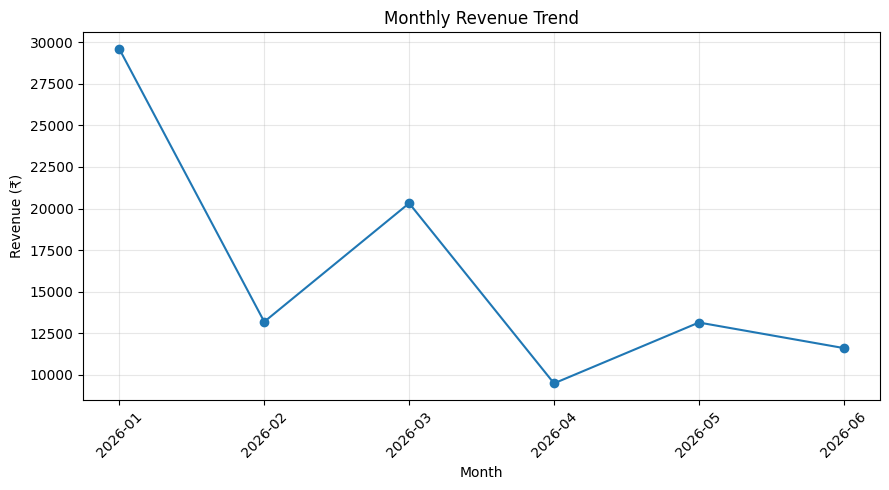

Monthly revenue chart saved!


In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    monthly_revenue["month"],
    monthly_revenue["total_revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("monthly_revenue.png", dpi=150)
plt.show()

print("Monthly revenue chart saved!")

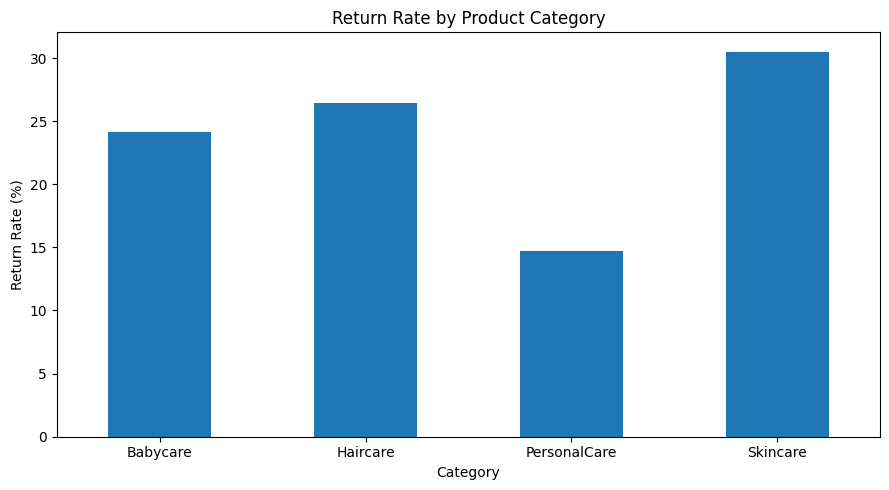

Return-rate chart saved!


In [26]:
return_analysis = merged_data.groupby("category")["returned"].mean() * 100

plt.figure(figsize=(9, 5))
return_analysis.plot(kind="bar")
plt.title("Return Rate by Product Category")
plt.xlabel("Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("return_rate.png", dpi=150)
plt.show()

print("Return-rate chart saved!")

In [27]:
from google.colab import files

files.download("monthly_revenue.png")
files.download("return_rate.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
total_orders = merged_data["order_id"].nunique()
total_customers = merged_data["customer_id"].nunique()
total_revenue = merged_data["revenue"].sum()
average_order_value = total_revenue / total_orders
overall_return_rate = merged_data["returned"].mean() * 100

top_category = category_analysis.loc[
    category_analysis["total_revenue"].idxmax(), "category"
]

top_month = monthly_revenue.loc[
    monthly_revenue["total_revenue"].idxmax(), "month"
]

print("PROJECT FINDINGS")
print("----------------")
print("Total orders:", total_orders)
print("Unique customers:", total_customers)
print("Total revenue: ₹", round(total_revenue, 2))
print("Average order value: ₹", round(average_order_value, 2))
print("Overall return rate:", round(overall_return_rate, 2), "%")
print("Top revenue category:", top_category)
print("Highest revenue month:", top_month)

PROJECT FINDINGS
----------------
Total orders: 175
Unique customers: 44
Total revenue: ₹ 97358.3
Average order value: ₹ 556.33
Overall return rate: 25.14 %
Top revenue category: Haircare
Highest revenue month: 2026-01


In [29]:
import json

findings = {
    "total_orders": int(total_orders),
    "unique_customers": int(total_customers),
    "total_revenue": round(float(total_revenue), 2),
    "average_order_value": round(float(average_order_value), 2),
    "overall_return_rate_percent": round(float(overall_return_rate), 2),
    "top_revenue_category": str(top_category),
    "highest_revenue_month": str(top_month)
}

with open("findings.json", "w") as f:
    json.dump(findings, f, indent=4)

print(json.dumps(findings, indent=4))
print("\nfindings.json saved successfully!")

{
    "total_orders": 175,
    "unique_customers": 44,
    "total_revenue": 97358.3,
    "average_order_value": 556.33,
    "overall_return_rate_percent": 25.14,
    "top_revenue_category": "Haircare",
    "highest_revenue_month": "2026-01"
}

findings.json saved successfully!


In [30]:

import json

with open("findings.json", "r") as f:
    findings = json.load(f)

narrative = f"""
Mamaearth Sales Analysis — Business Insights

The analysis covers {findings['total_orders']} cleaned orders from
{findings['unique_customers']} unique customers.

Total revenue was ₹{findings['total_revenue']:,.2f}, with an average
order value of ₹{findings['average_order_value']:,.2f}.

The overall return rate was {findings['overall_return_rate_percent']}%.
The {findings['top_revenue_category']} category generated the highest
revenue, while {findings['highest_revenue_month']} was the highest-revenue
month.

Business Recommendations:
1. Study successful Haircare products and use their strengths to improve sales.
2. Investigate reasons for returns, especially in high-return categories.
3. Analyse monthly sales patterns to plan promotions and inventory.
4. Monitor average order value and customer purchasing behaviour.
"""

with open("genai_narrative.txt", "w", encoding="utf-8") as f:
    f.write(narrative.strip())

print(narrative)
print("\ngenai_narrative.txt saved successfully!")



Mamaearth Sales Analysis — Business Insights

The analysis covers 175 cleaned orders from
44 unique customers.

Total revenue was ₹97,358.30, with an average
order value of ₹556.33.

The overall return rate was 25.14%.
The Haircare category generated the highest
revenue, while 2026-01 was the highest-revenue
month.

Business Recommendations:
1. Study successful Haircare products and use their strengths to improve sales.
2. Investigate reasons for returns, especially in high-return categories.
3. Analyse monthly sales patterns to plan promotions and inventory.
4. Monitor average order value and customer purchasing behaviour.


genai_narrative.txt saved successfully!


In [31]:

import json

with open("findings.json", "r") as f:
    findings = json.load(f)

with open("genai_narrative.txt", "r", encoding="utf-8") as f:
    narrative = f.read()

checks = {
    "Total orders": str(findings["total_orders"]) in narrative,
    "Unique customers": str(findings["unique_customers"]) in narrative,
    "Total revenue": f'{findings["total_revenue"]:,.2f}' in narrative,
    "Average order value": f'{findings["average_order_value"]:,.2f}' in narrative,
    "Return rate": f'{findings["overall_return_rate_percent"]}%' in narrative,
    "Top category": findings["top_revenue_category"] in narrative,
    "Highest revenue month": findings["highest_revenue_month"] in narrative
}

print("NUMERIC ACCURACY CHECK")
for item, passed in checks.items():
    print(f"{item}: {'PASS' if passed else 'FAIL'}")

print("\nOverall result:", "PASS" if all(checks.values()) else "CHECK REQUIRED")


NUMERIC ACCURACY CHECK
Total orders: PASS
Unique customers: PASS
Total revenue: PASS
Average order value: PASS
Return rate: PASS
Top category: PASS
Highest revenue month: PASS

Overall result: PASS


In [32]:

readme = """
# Mamaearth Sales Data Analysis

## Project Overview
This project analyses Mamaearth sales data using Python, SQL,
and data visualisation to identify sales trends and business insights.

## Objectives
- Clean and prepare sales data.
- Combine orders, customers, and products data.
- Analyse revenue and product categories.
- Examine monthly sales and product return rates.
- Generate business insights and recommendations.

## Tools Used
- Python
- Pandas
- Matplotlib
- MySQL
- Google Colab
- JSON

## Dataset Summary
- Cleaned orders: 175
- Unique customers: 44
- Total revenue: Rs. 97,358.30
- Average order value: Rs. 556.33
- Overall return rate: 25.14%

## Key Findings
- Haircare generated the highest revenue.
- January 2026 had the highest monthly revenue.
- Skincare had the highest category return rate.
- PersonalCare had the lowest category return rate.

## Business Recommendations
1. Study successful Haircare products to identify sales opportunities.
2. Investigate product returns, particularly in high-return categories.
3. Use monthly sales trends to improve inventory and promotion planning.
4. Monitor customer behaviour and average order value.

## Project Files
- cleaned_mamaearth_data.csv
- findings.json
- genai_narrative.txt
- monthly_revenue.png
- return_rate.png
- README.md

## Conclusion
The analysis provides insights into sales performance, customer
orders, revenue trends, and product returns that can support
data-driven business decisions.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip())

print("README.md saved successfully!")
print("\n", readme)


README.md saved successfully!

 
# Mamaearth Sales Data Analysis

## Project Overview
This project analyses Mamaearth sales data using Python, SQL,
and data visualisation to identify sales trends and business insights.

## Objectives
- Clean and prepare sales data.
- Combine orders, customers, and products data.
- Analyse revenue and product categories.
- Examine monthly sales and product return rates.
- Generate business insights and recommendations.

## Tools Used
- Python
- Pandas
- Matplotlib
- MySQL
- Google Colab
- JSON

## Dataset Summary
- Cleaned orders: 175
- Unique customers: 44
- Total revenue: Rs. 97,358.30
- Average order value: Rs. 556.33
- Overall return rate: 25.14%

## Key Findings
- Haircare generated the highest revenue.
- January 2026 had the highest monthly revenue.
- Skincare had the highest category return rate.
- PersonalCare had the lowest category return rate.

## Business Recommendations
1. Study successful Haircare products to identify sales opportunities.


In [33]:

import os
import zipfile

files_to_pack = [
    "cleaned_mamaearth_data.csv",
    "findings.json",
    "genai_narrative.txt",
    "monthly_revenue.png",
    "return_rate.png",
    "README.md"
]

available_files = [f for f in files_to_pack if os.path.exists(f)]
missing_files = [f for f in files_to_pack if not os.path.exists(f)]

print("Files found:", len(available_files), "out of", len(files_to_pack))
for f in available_files:
    print("✅", f)

if missing_files:
    print("\nFiles not found:")
    for f in missing_files:
        print("⚠️", f)

with zipfile.ZipFile("Mamaearth_Project_Deliverables.zip", "w",
                     zipfile.ZIP_DEFLATED) as zipf:
    for f in available_files:
        zipf.write(f)

print("\nZIP created: Mamaearth_Project_Deliverables.zip")

from google.colab import files
files.download("Mamaearth_Project_Deliverables.zip")


Files found: 6 out of 6
✅ cleaned_mamaearth_data.csv
✅ findings.json
✅ genai_narrative.txt
✅ monthly_revenue.png
✅ return_rate.png
✅ README.md

ZIP created: Mamaearth_Project_Deliverables.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>